In [12]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

## Load the Wine Quality Dataset

In [13]:
red_url='https://raw.githubusercontent.com/simonneutert/wine_quality_data/master/winequality-red.csv'
white_url='https://raw.githubusercontent.com/simonneutert/wine_quality_data/master/winequality-white.csv'

red=pd.read_csv(red_url,sep=';')
white=pd.read_csv(white_url,sep=';')
red['type']='red'
white['type']='white'

df=pd.concat([red,white],ignore_index=True)
print(df.shape)
df.head()

(6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [14]:
df.info()
print()
print(df.isnull().sum().sum(),'missing values')
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  type                  6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB

0 missing values


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


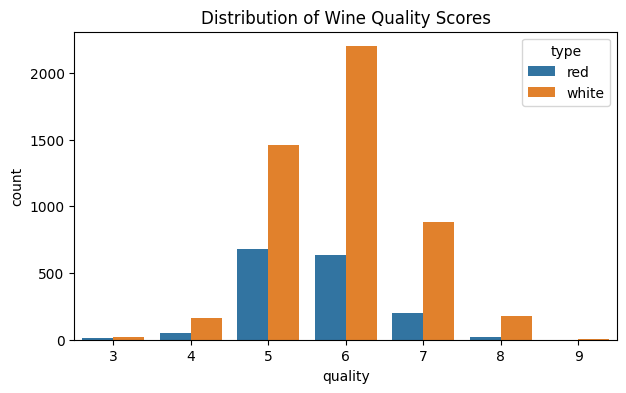

In [15]:
plt.figure(figsize=(7,4))
sns.countplot(data=df,x='quality',hue='type')
plt.title('Distribution of Wine Quality Scores')
plt.show()

## Preprocess the Dataset
The raw `quality` column is an integer score from 0-10 (in this data, scores actually range 3-9), and the classes are heavily imbalanced (very few wines score 3, 4, 8, or 9 — most cluster around 5-6). To get a cleaner, more balanced classification task for comparing network architectures, `quality` is **binarized**: wines scoring **7 or above are labeled `good_quality = 1`**, everything else is `0`. This is a standard simplification used for this dataset. The categorical `type` column (red/white) is **one-hot encoded** into a numeric feature, and all features are **standardized** (zero mean, unit variance) — essential for MLP training as discussed above.

In [16]:
df['good_quality']=(df['quality']>=7).astype(int)
df=pd.get_dummies(df,columns=['type'],drop_first=True)

print(df['good_quality'].value_counts())

X=df.drop(columns=['quality','good_quality'])
y=df['good_quality']
print(X.columns.tolist())

good_quality
0    5220
1    1277
Name: count, dtype: int64
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'type_white']


In [17]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

print(X_train_scaled.shape,X_test_scaled.shape)

(5197, 12) (1300, 12)


## Baseline MLP (Single Hidden Layer)

In [18]:
baseline=MLPClassifier(hidden_layer_sizes=(100,),activation='relu',solver='adam',max_iter=500,random_state=42)
baseline.fit(X_train_scaled,y_train)
y_pred=baseline.predict(X_test_scaled)

print('Accuracy :',accuracy_score(y_test,y_pred))
print('Precision:',precision_score(y_test,y_pred))
print('Recall   :',recall_score(y_test,y_pred))
print('F1-score :',f1_score(y_test,y_pred))
print('Converged in',baseline.n_iter_,'iterations')
print()
print(classification_report(y_test,y_pred))

Accuracy : 0.8376923076923077
Precision: 0.6285714285714286
Recall   : 0.4296875
F1-score : 0.5104408352668214
Converged in 500 iterations

              precision    recall  f1-score   support

           0       0.87      0.94      0.90      1044
           1       0.63      0.43      0.51       256

    accuracy                           0.84      1300
   macro avg       0.75      0.68      0.71      1300
weighted avg       0.82      0.84      0.83      1300



## Experiment with Different Architectures
A range of architectures is tried, varying both **width** (neurons per layer) and **depth** (number of hidden layers), to see how each choice affects accuracy, F1-score, and training time.

In [19]:
architectures={
    '1 layer - (10)':(10,),
    '1 layer - (50)':(50,),
    '1 layer - (100)':(100,),
    '2 layers - (50,50)':(50,50),
    '2 layers - (100,50)':(100,50),
    '3 layers - (100,50,25)':(100,50,25),
}

results=[]
trained_models={}
for name,arch in architectures.items():
    t0=time.time()
    model=MLPClassifier(hidden_layer_sizes=arch,activation='relu',solver='adam',max_iter=500,random_state=42)
    model.fit(X_train_scaled,y_train)
    train_time=time.time()-t0
    pred=model.predict(X_test_scaled)
    n_params=sum(c.size for c in model.coefs_)+sum(c.size for c in model.intercepts_)
    results.append({
        'Architecture':name,
        'Hidden Layers':len(arch),
        'Total Params':n_params,
        'Accuracy':accuracy_score(y_test,pred),
        'Precision':precision_score(y_test,pred),
        'Recall':recall_score(y_test,pred),
        'F1-score':f1_score(y_test,pred),
        'Iterations':model.n_iter_,
        'Train Time (s)':train_time
    })
    trained_models[name]=model

results_df=pd.DataFrame(results)
results_df

,Architecture,Hidden Layers,Total Params,Accuracy,Precision,Recall,F1-score,Iterations,Train Time (s)
0,1 layer - (10),1,141,0.823077,0.582278,0.359375,0.444444,260,0.791527
1,1 layer - (50),1,701,0.831538,0.614907,0.386719,0.474820,500,2.425332
2,1 layer - (100),1,1401,0.837692,0.628571,0.429688,0.510441,500,3.442798
3,"2 layers - (50,50)",2,3251,0.844615,0.608871,0.589844,0.599206,500,4.618126
4,"2 layers - (100,50)",2,6401,0.856923,0.632576,0.652344,0.642308,447,5.545171
5,"3 layers - (100,50,25)",3,7651,0.861538,0.674312,0.574219,0.620253,261,3.887657


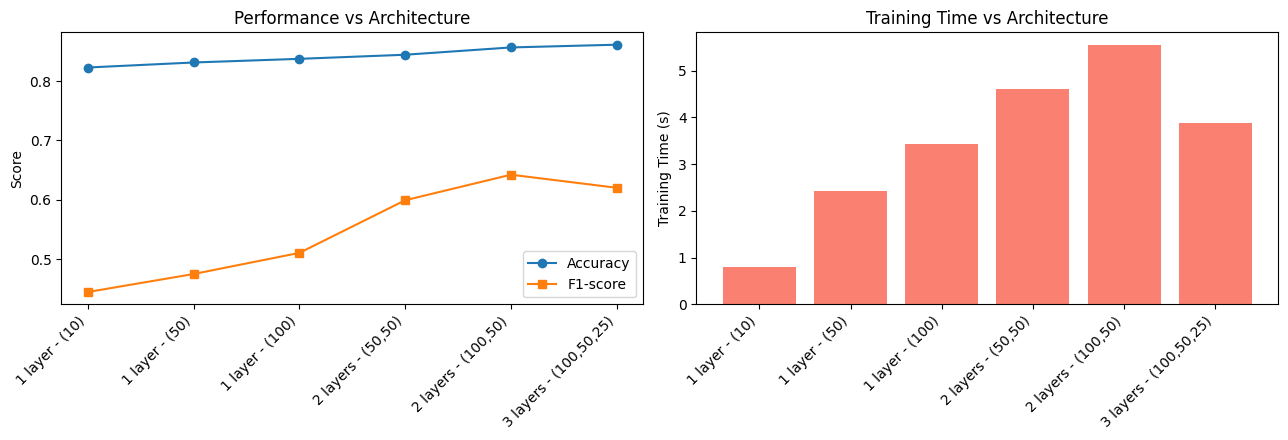

In [20]:
fig,axes=plt.subplots(1,2,figsize=(13,4.5))

x=np.arange(len(results_df))
axes[0].plot(x,results_df['Accuracy'],marker='o',label='Accuracy')
axes[0].plot(x,results_df['F1-score'],marker='s',label='F1-score')
axes[0].set_xticks(x)
axes[0].set_xticklabels(results_df['Architecture'],rotation=45,ha='right')
axes[0].set_ylabel('Score')
axes[0].set_title('Performance vs Architecture')
axes[0].legend()

axes[1].bar(x,results_df['Train Time (s)'],color='salmon')
axes[1].set_xticks(x)
axes[1].set_xticklabels(results_df['Architecture'],rotation=45,ha='right')
axes[1].set_ylabel('Training Time (s)')
axes[1].set_title('Training Time vs Architecture')

plt.tight_layout()
plt.show()

## Convergence Behavior — Loss Curves
Plotting the training loss over iterations for a few representative architectures shows *how* each one learns, not just its final score — shallow/narrow networks may plateau early, while deeper/wider networks can keep reducing loss for longer (and are more prone to overfitting if allowed to run indefinitely).

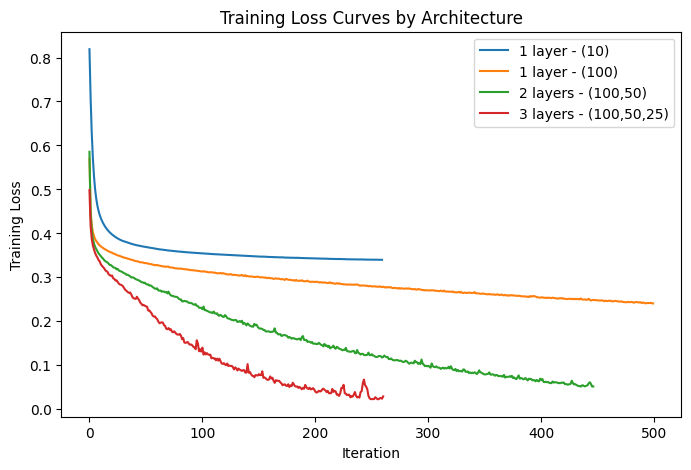

In [21]:
plt.figure(figsize=(8,5))
for name in ['1 layer - (10)','1 layer - (100)','2 layers - (100,50)','3 layers - (100,50,25)']:
    plt.plot(trained_models[name].loss_curve_,label=name)
plt.xlabel('Iteration')
plt.ylabel('Training Loss')
plt.title('Training Loss Curves by Architecture')
plt.legend()
plt.show()

## Confusion Matrix for the Best-Performing Architecture

Best architecture (by F1-score): 2 layers - (100,50)


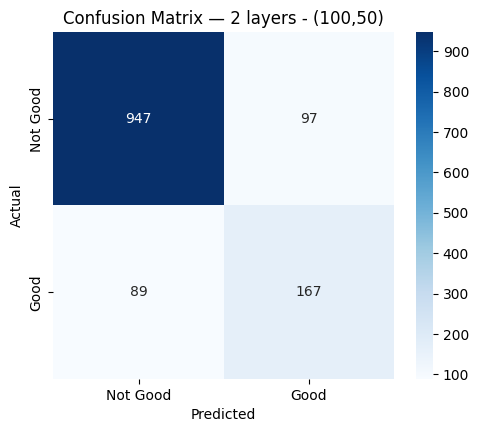

In [22]:
best_name=results_df.loc[results_df['F1-score'].idxmax(),'Architecture']
best_model=trained_models[best_name]
print('Best architecture (by F1-score):',best_name)

y_pred_best=best_model.predict(X_test_scaled)
cm=confusion_matrix(y_test,y_pred_best)

plt.figure(figsize=(5.5,4.5))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=['Not Good','Good'],yticklabels=['Not Good','Good'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Confusion Matrix — {best_name}')
plt.show()